# Notebook 4 — Classification & Evaluation

**Notebook 4 of 4.** Train three classifiers (**XGBoost** primary, **Random Forest**, **Neural Network**) on each of the 18 augmented training sets (6 generators × 3 imbalance ratios) and evaluate on the **held-out REAL test set**.

Generators: `none` (baseline), `ctgan`, `tvae`, `smote`, `adasyn`, `ros`.

**Every result is measured on real fraud the model never saw** (no synthetic data in test). Metrics: Precision, Recall, F1, PR-AUC, ROC-AUC — reported for the **fraud class**, which is what matters under imbalance.

Output: `results.csv` — the master results table for the paper.

In [ ]:
!pip install -q xgboost scikit-learn

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROC_DIR = '/content/drive/MyDrive/SDG_paper/data/processed'
AUG_DIR  = '/content/drive/MyDrive/SDG_paper/data/augmented'
RES_DIR  = '/content/drive/MyDrive/SDG_paper/results'

import os
os.makedirs(RES_DIR, exist_ok=True)

Mounted at /content/drive


In [ ]:
import pandas as pd, numpy as np, json, time, warnings
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

RATIOS = [100, 500, 1000]
GENERATORS = ['none', 'ctgan', 'tvae', 'smote', 'adasyn', 'ros']

with open(os.path.join(PROC_DIR, 'feature_cols.json')) as f:
    FEATURES = json.load(f)

# Real, untouched evaluation data (same for every run)
val  = pd.read_parquet(os.path.join(PROC_DIR, 'val.parquet'))
test = pd.read_parquet(os.path.join(PROC_DIR, 'test.parquet'))
X_val,  y_val  = val[FEATURES],  val['label']
X_test, y_test = test[FEATURES], test['label']
print('Test set:', X_test.shape, '| real fraud in test:', int(y_test.sum()))

Test set: (154031, 74) | real fraud in test: 13319


## 1. Classifier builders & evaluation

The decision threshold is tuned on the **validation** set (to maximize fraud F1), then applied unchanged to the test set — so we never peek at the test set when choosing the threshold.

In [ ]:
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score)

def make_models():
    return {
        'xgboost': XGBClassifier(
            n_estimators=300, max_depth=6, learning_rate=0.1,
            subsample=0.8, colsample_bytree=0.8, tree_method='hist',
            eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1),
        'random_forest': RandomForestClassifier(
            n_estimators=200, max_depth=None, n_jobs=-1,
            random_state=RANDOM_STATE),
        'neural_net': MLPClassifier(
            hidden_layer_sizes=(128, 64), early_stopping=True,
            max_iter=60, random_state=RANDOM_STATE),
    }

def best_threshold(y_true, scores):
    """Threshold that maximizes fraud-class F1 on validation."""
    best_t, best_f1 = 0.5, -1
    for t in np.linspace(0.05, 0.95, 19):
        f1 = f1_score(y_true, (scores >= t).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    return best_t

def evaluate(model, X_tr, y_tr):
    model.fit(X_tr, y_tr)
    val_scores  = model.predict_proba(X_val)[:, 1]
    test_scores = model.predict_proba(X_test)[:, 1]
    t = best_threshold(y_val, val_scores)
    y_pred = (test_scores >= t).astype(int)
    return {
        'precision': precision_score(y_test, y_pred, zero_division=0),
        'recall':    recall_score(y_test, y_pred, zero_division=0),
        'f1':        f1_score(y_test, y_pred, zero_division=0),
        'pr_auc':    average_precision_score(y_test, test_scores),
        'roc_auc':   roc_auc_score(y_test, test_scores),
        'threshold': round(float(t), 3),
    }

## 2. Run everything (18 augmented sets × 3 classifiers = 54 runs)

The heavy cell. Results stream to a CSV after every run, so a disconnect doesn't lose completed work — re-running skips rows already in the CSV.

In [ ]:
results_path = os.path.join(RES_DIR, 'results.csv')
done = set()
if os.path.exists(results_path):
    prev = pd.read_csv(results_path)
    done = set(zip(prev['ratio'], prev['generator'], prev['classifier']))
    print(f'Resuming — {len(done)} runs already done.')

all_rows = []
for r in RATIOS:
    for gen in GENERATORS:
        path = os.path.join(AUG_DIR, f'aug_1_{r}_{gen}.parquet')
        if not os.path.exists(path):
            print(f'  missing {path} — skipping'); continue
        train = pd.read_parquet(path)
        X_tr, y_tr = train[FEATURES], train['label']
        for name, model in make_models().items():
            if (r, gen, name) in done:
                continue
            t0 = time.time()
            m = evaluate(model, X_tr, y_tr)
            m.update({'ratio': r, 'generator': gen, 'classifier': name,
                      'secs': round(time.time()-t0, 1)})
            all_rows.append(m)
            # append-save immediately
            pd.DataFrame([m]).to_csv(results_path, mode='a', index=False,
                                     header=not os.path.exists(results_path))
            print(f"1:{r:<4} {gen:<7} {name:<13} F1={m['f1']:.3f} "
                  f"PR-AUC={m['pr_auc']:.3f} rec={m['recall']:.3f} ({m['secs']}s)")

print('\nAll runs complete. Results in', results_path)

Resuming — 16 runs already done.
1:100  ros     random_forest F1=0.999 PR-AUC=1.000 rec=0.999 (15.3s)
1:100  ros     neural_net    F1=0.996 PR-AUC=1.000 rec=0.995 (61.5s)
1:500  none    xgboost       F1=0.991 PR-AUC=1.000 rec=0.983 (3.4s)
1:500  none    random_forest F1=0.998 PR-AUC=1.000 rec=0.998 (10.5s)
1:500  none    neural_net    F1=0.981 PR-AUC=0.997 rec=0.967 (29.6s)
1:500  ctgan   xgboost       F1=0.992 PR-AUC=1.000 rec=0.984 (6.0s)
1:500  ctgan   random_forest F1=0.997 PR-AUC=1.000 rec=0.998 (48.1s)
1:500  ctgan   neural_net    F1=0.976 PR-AUC=0.997 rec=0.967 (46.2s)
1:500  tvae    xgboost       F1=0.993 PR-AUC=1.000 rec=0.986 (5.1s)
1:500  tvae    random_forest F1=0.998 PR-AUC=1.000 rec=0.999 (66.9s)
1:500  tvae    neural_net    F1=0.979 PR-AUC=0.996 rec=0.966 (45.3s)
1:500  smote   xgboost       F1=0.995 PR-AUC=1.000 rec=0.991 (5.1s)
1:500  smote   random_forest F1=0.999 PR-AUC=1.000 rec=0.999 (32.6s)
1:500  smote   neural_net    F1=0.983 PR-AUC=0.996 rec=0.967 (59.8s)
1:500

## 3. Results tables for the paper

In [ ]:
res = pd.read_csv(results_path)
res['generator'] = pd.Categorical(res['generator'], GENERATORS, ordered=True)

# --- Main table: XGBoost (primary classifier), F1 by generator × ratio ---
print('=== XGBoost — fraud F1 by generator and imbalance ratio ===')
xgb = res[res['classifier'] == 'xgboost']
print(xgb.pivot_table(index='generator', columns='ratio', values='f1').round(3))

print('\n=== XGBoost — fraud PR-AUC by generator and imbalance ratio ===')
print(xgb.pivot_table(index='generator', columns='ratio', values='pr_auc').round(3))

=== XGBoost — fraud F1 by generator and imbalance ratio ===
ratio       100    500    1000
generator                     
none       0.999  0.991  0.976
ctgan      0.999  0.992  0.980
tvae       0.999  0.993  0.979
smote      0.999  0.995  0.990
adasyn     0.999  0.996  0.990
ros        0.999  0.995  0.986

=== XGBoost — fraud PR-AUC by generator and imbalance ratio ===
ratio      100   500    1000
generator                   
none        1.0   1.0  0.998
ctgan       1.0   1.0  0.998
tvae        1.0   1.0  0.998
smote       1.0   1.0  0.999
adasyn      1.0   1.0  0.998
ros         1.0   1.0  0.998


In [ ]:
# --- Full per-classifier view at the hardest ratio (1:1000) ---
print('=== All classifiers at 1:1000 (F1 / PR-AUC / recall) ===')
hard = res[res['ratio'] == 1000].copy()
print(hard.pivot_table(index='generator', columns='classifier',
                       values='f1').round(3))

=== All classifiers at 1:1000 (F1 / PR-AUC / recall) ===
classifier  neural_net  random_forest  xgboost
generator                                     
none             0.975          0.996    0.976
ctgan            0.968          0.997    0.980
tvae             0.964          0.996    0.979
smote            0.974          0.999    0.990
adasyn           0.968          0.997    0.990
ros              0.974          0.994    0.986


In [ ]:
# --- The headline story: does augmentation help, and does its benefit grow with imbalance? ---
# Improvement in XGBoost F1 vs the no-augmentation baseline, per ratio.
piv = xgb.pivot_table(index='generator', columns='ratio', values='f1')
baseline = piv.loc['none']
improvement = (piv - baseline).drop(index='none').round(3)
print('=== F1 improvement over no-augmentation baseline (XGBoost) ===')
print(improvement)
print('\n(If the numbers grow left->right across ratios, augmentation helps more as fraud gets scarcer.)')

=== F1 improvement over no-augmentation baseline (XGBoost) ===
ratio      100    500    1000
generator                    
ctgan       0.0  0.001  0.005
tvae        0.0  0.001  0.003
smote       0.0  0.004  0.014
adasyn      0.0  0.005  0.015
ros         0.0  0.004  0.010

(If the numbers grow left->right across ratios, augmentation helps more as fraud gets scarcer.)


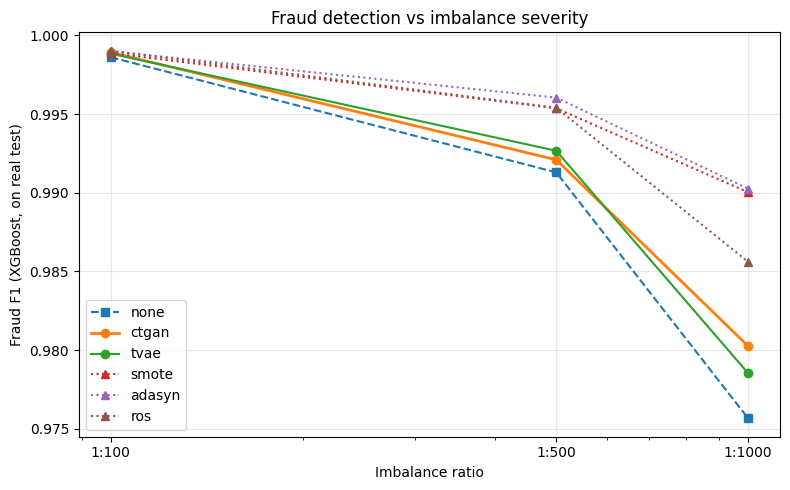

In [ ]:
# --- Quick visualization: F1 vs imbalance, one line per generator (XGBoost) ---
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8,5))
for gen in GENERATORS:
    sub = xgb[xgb['generator'] == gen].sort_values('ratio')
    style = '-o' if gen in ('ctgan','tvae') else ('--s' if gen=='none' else ':^')
    ax.plot(sub['ratio'], sub['f1'], style, label=gen, linewidth=2 if gen=='ctgan' else 1.5)
ax.set_xscale('log'); ax.set_xticks(RATIOS); ax.set_xticklabels([f'1:{r}' for r in RATIOS])
ax.set_xlabel('Imbalance ratio'); ax.set_ylabel('Fraud F1 (XGBoost, on real test)')
ax.set_title('Fraud detection vs imbalance severity'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(RES_DIR,'f1_vs_imbalance.png'), dpi=150); plt.show()

In [ ]:
# ============================================================
#  LEAKAGE / "too-good-to-be-true" DIAGNOSTIC
# ============================================================
import numpy as np, pandas as pd, os, json
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import f1_score

with open(os.path.join(PROC_DIR, 'feature_cols.json')) as f:
    FEATURES = json.load(f)

# Use the natural-distribution training data (full fraud, no augmentation)
# Rebuild a modest balanced sample straight from the processed splits:
tr = pd.read_parquet(os.path.join(PROC_DIR, 'train_1_100.parquet'))  # has real fraud + legit
# take all fraud + an equal number of legit for a clean diagnostic
fraud = tr[tr.label==1]; legit = tr[tr.label==0].sample(len(fraud), random_state=42)
diag = pd.concat([fraud, legit]).sample(frac=1, random_state=42)
Xd, yd = diag[FEATURES], diag['label']

# ---- CHECK 1: Feature importance — is ONE feature carrying everything? ----
clf = XGBClassifier(n_estimators=200, max_depth=6, tree_method='hist',
                    eval_metric='logloss', random_state=42, n_jobs=-1)
clf.fit(Xd, yd)
imp = pd.Series(clf.feature_importances_, index=FEATURES).sort_values(ascending=False)
print('=== Top 15 feature importances ===')
print(imp.head(15).round(4))
print(f'\nTop feature alone = {imp.iloc[0]:.1%} of importance')
print(f'Top 3 features    = {imp.head(3).sum():.1%} of importance')

# ---- CHECK 2: Can a SINGLE feature already near-perfectly classify? ----
print('\n=== Best single-feature F1 (5-fold CV) for top features ===')
for feat in imp.head(5).index:
    stump = XGBClassifier(n_estimators=50, max_depth=2, tree_method='hist',
                          eval_metric='logloss', random_state=42, n_jobs=-1)
    s = cross_val_score(stump, Xd[[feat]], yd, cv=5, scoring='f1')
    print(f'  {feat:40s} F1={s.mean():.3f}')

# ---- CHECK 3: Drop the top features, does performance collapse? ----
# If removing the few dominant features tanks F1, they ARE the leak.
print('\n=== F1 after removing top-k features (5-fold CV) ===')
for k in [0, 1, 3, 5, 10]:
    drop = imp.head(k).index.tolist()
    cols = [c for c in FEATURES if c not in drop]
    clf2 = XGBClassifier(n_estimators=200, max_depth=6, tree_method='hist',
                         eval_metric='logloss', random_state=42, n_jobs=-1)
    s = cross_val_score(clf2, Xd[cols], yd, cv=5, scoring='f1')
    print(f'  remove top {k:2d}: F1={s.mean():.3f}  (dropped: {drop[:3]}{"..." if k>3 else ""})')

=== Top 15 feature importances ===
nonce.nonce_median                                        0.3398
cumulativeGasUsed.cumulativeGasUsed_standard_deviation    0.1628
cumulativeGasUsed.cumulativeGasUsed_mode                  0.0962
gas_prices.gas_prices_maximum_val                         0.0556
gas_prices.gas_prices_summation                           0.0463
gas_prices.gas_prices_minimum_val                         0.0374
num_transaction                                           0.0330
values.values_average                                     0.0151
cumulativeGasUsed.cumulativeGasUsed_skewness              0.0139
nonce.nonce_summation                                     0.0131
gas_used.gas_used_average                                 0.0128
nonce.nonce_mode                                          0.0106
values.values_coefficient_of_variation                    0.0099
values.values_median                                      0.0097
number_of_unique_to_address                            